In [1]:
!pip install -q kagglehub scikit-image opencv-python-headless scikit-learn tqdm # libraries installed
print("✅ Libraries installed")

✅ Libraries installed


In [2]:
import os, json, time, random, math# imported the required librarires.
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import models

from skimage.metrics import peak_signal_noise_ratio as sk_psnr
from skimage.metrics import structural_similarity as sk_ssim
from sklearn.model_selection import train_test_split

SEED = 42
IMG_SIZE = 256
IMG_EXT = ('.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff')

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
set_seed()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("Device :", device)
if device.type == "cuda":
    print("GPU    :", torch.cuda.get_device_name(0))
else:
    print("⚠️ No GPU detected. Runtime > Change runtime type > T4 GPU, then re-run from Cell 1.")

PyTorch: 2.14.1+cu130
Device : cuda
GPU    : Tesla T4


In [3]:
RESULTS_DIR = '/content/AquaVision_Results'# created the directory
FIG_DIR     = os.path.join(RESULTS_DIR, 'figures')
CKPT_DIR    = os.path.join(RESULTS_DIR, 'checkpoints')
for d in (RESULTS_DIR, FIG_DIR, CKPT_DIR):
    os.makedirs(d, exist_ok=True)
print("✅ Local results folder:", RESULTS_DIR)

✅ Local results folder: /content/AquaVision_Results


In [4]:
import kagglehub
#Imported datset
DATASET_PATH = kagglehub.dataset_download("pamuduranasinghe/euvp-dataset")
print("✅ Dataset path:", DATASET_PATH)
print("Top-level contents:", os.listdir(DATASET_PATH))

Using Colab cache for faster access to the 'euvp-dataset' dataset.
✅ Dataset path: /kaggle/input/euvp-dataset
Top-level contents: ['EUVP']


In [5]:
def show_tree(root, max_depth=6):#folder structure
    total = 0
    for cur, dirs, files in os.walk(root):
        depth = cur[len(root):].count(os.sep)
        if depth > max_depth:
            dirs[:] = []
            continue
        dirs.sort()
        n = sum(f.lower().endswith(IMG_EXT) for f in files)
        total += n
        print(f"{'   ' * depth}📁 {os.path.basename(cur) or cur}  [{n} images]")
    return total

total_found = show_tree(DATASET_PATH)
print("\nTotal images found:", total_found)

📁 euvp-dataset  [0 images]
   📁 EUVP  [0 images]
      📁 Paired  [0 images]
         📁 underwater_dark  [0 images]
            📁 trainA  [5550 images]
            📁 trainB  [5550 images]
            📁 validation  [570 images]
         📁 underwater_imagenet  [0 images]
            📁 trainA  [3700 images]
            📁 trainB  [3700 images]
            📁 validation  [1270 images]
         📁 underwater_scenes  [0 images]
            📁 trainA  [2185 images]
            📁 trainB  [2185 images]
            📁 validation  [130 images]
      📁 Unpaired  [0 images]
         📁 trainA  [3205 images]
         📁 trainB  [3140 images]
         📁 validation  [330 images]
      📁 eval_data  [0 images]
         📁 euvp_test  [0 images]
            📁 deep-sesr  [0 images]
               📁 deep-sesr  [515 images]
            📁 funie-gan  [0 images]
               📁 funie-gan  [515 images]
            📁 funie-gan-up  [0 images]
               📁 funie-gan-up  [515 images]
            📁 ugan  [0 images]
     

In [6]:
A_NAMES = {'traina', 'input', 'inputs', 'inp', 'distorted', 'degraded', 'lq', 'raw'}# distinguished the images paired and unpaired
B_NAMES = {'trainb', 'gt', 'target', 'targets', 'reference', 'ground_truth', 'groundtruth', 'hq', 'ref'}

dir_images = {}
for cur, dirs, files in os.walk(DATASET_PATH):
    imgs = sorted(f for f in files if f.lower().endswith(IMG_EXT))
    if imgs:
        dir_images[cur] = imgs
total_images = sum(len(v) for v in dir_images.values())

pair_rows, unpaired_paths, used_dirs = [], [], set()

for d, imgs in dir_images.items():
    rel = os.path.relpath(d, DATASET_PATH)
    if 'unpaired' in rel.lower():                       # unpaired images: never used for supervised metrics
        unpaired_paths += [os.path.join(d, f) for f in imgs]
        used_dirs.add(d)
        continue
    if os.path.basename(d).lower() in A_NAMES:
        parent = os.path.dirname(d)
        for sib in dir_images:
            if os.path.dirname(sib) == parent and os.path.basename(sib).lower() in B_NAMES:
                ref_map = {os.path.splitext(f)[0].lower(): os.path.join(sib, f) for f in dir_images[sib]}
                cat = os.path.relpath(parent, DATASET_PATH)
                n_match = 0
                for f in imgs:
                    key = os.path.splitext(f)[0].lower()
                    if key in ref_map:
                        pair_rows.append({'input': os.path.join(d, f), 'reference': ref_map[key], 'category': cat})
                        n_match += 1
                if n_match:
                    used_dirs.update([d, sib])

pairs_df = pd.DataFrame(pair_rows).drop_duplicates(subset=['input', 'reference']).reset_index(drop=True)

other_dirs = {d: len(v) for d, v in dir_images.items() if d not in used_dirs}
other_count = sum(other_dirs.values())

print("Total images in dataset      :", total_images)
print("Matched PAIRS (input+ref)    :", len(pairs_df), f"-> {2*len(pairs_df)} image files")
print("UNPAIRED images              :", len(unpaired_paths))
print("Other / unmatched images     :", other_count)
if other_dirs:
    print("\nFolders not used (check if any should be paired):")
    for d, n in other_dirs.items():
        print(f"  {os.path.relpath(d, DATASET_PATH)}  [{n}]")

if len(pairs_df) == 0:
    raise RuntimeError("No pairs detected. Paste the output of Cell 5 and Cell 6 so the matching rule can be fixed.")

print("\nPairs per category:")
print(pairs_df['category'].value_counts())

Total images in dataset      : 35720
Matched PAIRS (input+ref)    : 11435 -> 22870 image files
UNPAIRED images              : 6675
Other / unmatched images     : 6175

Folders not used (check if any should be paired):
  EUVP/eval_data/ufo_test/funie-gan-up/funie-gan-up  [120]
  EUVP/eval_data/ufo_test/ugan/ugan  [120]
  EUVP/eval_data/ufo_test/funie-gan/funie-gan  [120]
  EUVP/eval_data/ufo_test/deep-sesr/deep-sesr  [120]
  EUVP/eval_data/ufo_test/ugan-p/ugan-p  [120]
  EUVP/eval_data/euvp_test/funie-gan-up/funie-gan-up  [515]
  EUVP/eval_data/euvp_test/ugan/ugan  [515]
  EUVP/eval_data/euvp_test/funie-gan/funie-gan  [515]
  EUVP/eval_data/euvp_test/deep-sesr/deep-sesr  [515]
  EUVP/eval_data/euvp_test/ugan-p/ugan-p  [515]
  EUVP/test_samples/Inp  [515]
  EUVP/test_samples/GTr  [515]
  EUVP/Paired/underwater_imagenet/validation  [1270]
  EUVP/Paired/underwater_dark/validation  [570]
  EUVP/Paired/underwater_scenes/validation  [130]

Pairs per category:
category
EUVP/Paired/underwater_d

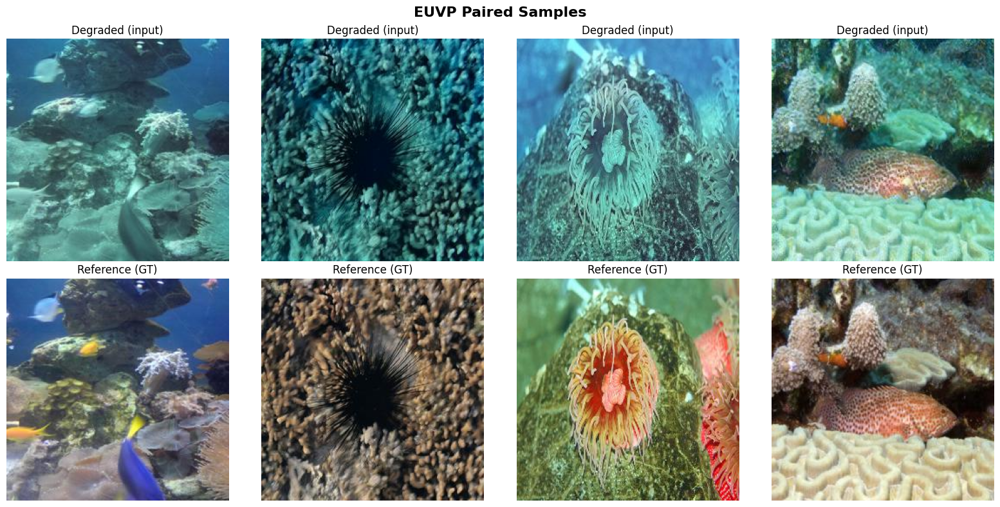

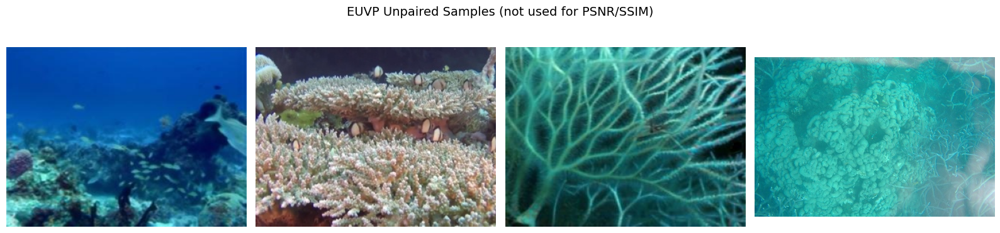

In [7]:
# count iamges and visialise samples
def read_rgb(path):
    img = cv2.imread(path, cv2.IMREAD_COLOR)
    if img is None:
        raise FileNotFoundError(f"Cannot read image: {path}")
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

n_show = 4
sample = pairs_df.sample(n_show, random_state=SEED).reset_index(drop=True)
fig, axes = plt.subplots(2, n_show, figsize=(4 * n_show, 8))
for i, r in sample.iterrows():
    axes[0, i].imshow(read_rgb(r['input']));     axes[0, i].set_title("Degraded (input)", fontsize=12); axes[0, i].axis('off')
    axes[1, i].imshow(read_rgb(r['reference'])); axes[1, i].set_title("Reference (GT)", fontsize=12);  axes[1, i].axis('off')
plt.suptitle("EUVP Paired Samples", fontsize=16, fontweight='bold')
plt.tight_layout(); plt.show()

if len(unpaired_paths) > 0:
    k = min(4, len(unpaired_paths))
    pick = random.Random(SEED).sample(unpaired_paths, k)
    fig, axes = plt.subplots(1, k, figsize=(4 * k, 4))
    axes = np.atleast_1d(axes)
    for ax, p in zip(axes, pick):
        ax.imshow(read_rgb(p)); ax.axis('off')
    plt.suptitle("EUVP Unpaired Samples (not used for PSNR/SSIM)", fontsize=14)
    plt.tight_layout(); plt.show()

In [8]:
strat = pairs_df['category'] if pairs_df['category'].value_counts().min() >= 2 else None # created 70/15/15 train,val, test split

train_df, temp_df = train_test_split(pairs_df, test_size=0.30, random_state=SEED, stratify=strat)
strat_t = temp_df['category'] if (strat is not None and temp_df['category'].value_counts().min() >= 2) else None
val_df, test_df = train_test_split(temp_df, test_size=0.50, random_state=SEED, stratify=strat_t)

train_df = train_df.reset_index(drop=True)
val_df   = val_df.reset_index(drop=True)
test_df  = test_df.reset_index(drop=True)

assert not (set(train_df['input']) & set(val_df['input']))
assert not (set(train_df['input']) & set(test_df['input']))
assert not (set(val_df['input'])   & set(test_df['input']))

n_total = len(pairs_df)
for name, d in [('Train', train_df), ('Val', val_df), ('Test', test_df)]:
    print(f"{name:5s}: {len(d):6d} pairs ({100*len(d)/n_total:.1f}%)")

pd.concat([train_df.assign(split='train'), val_df.assign(split='val'), test_df.assign(split='test')]) \
  .to_csv(os.path.join(RESULTS_DIR, 'dataset_splits.csv'), index=False)
print("✅ Split saved to Drive: dataset_splits.csv")

Train:   8004 pairs (70.0%)
Val  :   1715 pairs (15.0%)
Test :   1716 pairs (15.0%)
✅ Split saved to Drive: dataset_splits.csv


In [9]:
# preprocessing and sugumentation
def load_pair(inp_path, ref_path, size=IMG_SIZE):
    a = cv2.resize(read_rgb(inp_path), (size, size), interpolation=cv2.INTER_AREA)
    b = cv2.resize(read_rgb(ref_path), (size, size), interpolation=cv2.INTER_AREA)
    return a, b

def paired_augment(a, b):
    if random.random() < 0.5:
        a, b = a[:, ::-1], b[:, ::-1]          # horizontal flip
    if random.random() < 0.5:
        a, b = a[::-1, :], b[::-1, :]          # vertical flip
    k = random.randint(0, 3)
    if k:
        a, b = np.rot90(a, k), np.rot90(b, k)  # rotation by 90°
    return np.ascontiguousarray(a), np.ascontiguousarray(b)

def to_tensor(img):
    return torch.from_numpy(img).permute(2, 0, 1).float() / 255.0   # HWC uint8 -> CHW float [0,1]

# quick sanity test
a, b = load_pair(train_df.loc[0, 'input'], train_df.loc[0, 'reference'])
a2, b2 = paired_augment(a, b)
print("Loaded shapes:", a.shape, b.shape, "| dtype:", a.dtype)
print("Tensor shape :", to_tensor(a2).shape, "| range:", float(to_tensor(a2).min()), "-", float(to_tensor(a2).max()))

Loaded shapes: (256, 256, 3) (256, 256, 3) | dtype: uint8
Tensor shape : torch.Size([3, 256, 256]) | range: 0.0 - 1.0


In [10]:
# pytorch and dataset  and dataset loaders
from concurrent.futures import ThreadPoolExecutor

def cache_split(df, name):
    def _load(i):
        r = df.iloc[i]
        return load_pair(r['input'], r['reference'])
    with ThreadPoolExecutor(8) as ex:
        out = list(tqdm(ex.map(_load, range(len(df))), total=len(df), desc=f'Caching {name}'))
    X = np.stack([o[0] for o in out]); Y = np.stack([o[1] for o in out])
    del out
    return X, Y

class CachedPairDataset(Dataset):
    def __init__(self, X, Y, augment=False):
        self.X, self.Y, self.augment = X, Y, augment
    def __len__(self):
        return len(self.X)
    def __getitem__(self, idx):
        a, b = self.X[idx], self.Y[idx]
        if self.augment:
            a, b = paired_augment(a, b)
        return to_tensor(a), to_tensor(b)

BATCH_SIZE = 16
Xtr, Ytr = cache_split(train_df, 'train')
Xva, Yva = cache_split(val_df, 'val')
Xte, Yte = cache_split(test_df, 'test')

train_ds = CachedPairDataset(Xtr, Ytr, augment=True)
val_ds   = CachedPairDataset(Xva, Yva)
test_ds  = CachedPairDataset(Xte, Yte)

pin = device.type == 'cuda'
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  num_workers=0, pin_memory=pin, drop_last=True)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=pin)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=pin)

xb, yb = next(iter(train_loader))
print("Batch:", xb.shape, yb.shape, "| train/val/test batches:", len(train_loader), len(val_loader), len(test_loader))

Caching train:   0%|          | 0/8004 [00:00<?, ?it/s]

Caching val:   0%|          | 0/1715 [00:00<?, ?it/s]

Caching test:   0%|          | 0/1716 [00:00<?, ?it/s]

Batch: torch.Size([16, 3, 256, 256]) torch.Size([16, 3, 256, 256]) | train/val/test batches: 500 108 108


In [11]:
#dae-unet (RESNET18 ENCODER + RESIDUAL DECODER)
class ResBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False)
        self.bn1   = nn.BatchNorm2d(out_ch)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False)
        self.bn2   = nn.BatchNorm2d(out_ch)
        self.short = nn.Identity() if in_ch == out_ch else nn.Sequential(nn.Conv2d(in_ch, out_ch, 1, bias=False), nn.BatchNorm2d(out_ch))
    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)), inplace=True)
        out = self.bn2(self.conv2(out))
        return F.relu(out + self.short(x), inplace=True)

class UpBlock(nn.Module):
    """Upsample -> concat skip connection -> residual block."""
    def __init__(self, in_ch, skip_ch, out_ch):
        super().__init__()
        self.res = ResBlock(in_ch + skip_ch, out_ch)
    def forward(self, x, skip):
        x = F.interpolate(x, size=skip.shape[2:], mode='bilinear', align_corners=False)
        return self.res(torch.cat([x, skip], dim=1))

class DAEUNet(nn.Module):
    def __init__(self, pretrained=True):
        super().__init__()
        w = models.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None
        r = models.resnet18(weights=w)
        # ---- Encoder (ResNet18) ----
        self.conv1, self.bn1, self.pool = r.conv1, r.bn1, r.maxpool
        self.layer1, self.layer2, self.layer3, self.layer4 = r.layer1, r.layer2, r.layer3, r.layer4
        # ---- Residual decoder with skip connections ----
        self.up4 = UpBlock(512, 256, 256)   # 1/32 -> 1/16
        self.up3 = UpBlock(256, 128, 128)   # 1/16 -> 1/8
        self.up2 = UpBlock(128, 64, 64)     # 1/8  -> 1/4
        self.up1 = UpBlock(64, 64, 64)      # 1/4  -> 1/2
        self.up0 = UpBlock(64, 3, 32)       # 1/2  -> full resolution (raw input skip)
        self.head = nn.Conv2d(32, 3, 3, padding=1)
        nn.init.zeros_(self.head.weight); nn.init.zeros_(self.head.bias)   # start as identity mapping
        self.register_buffer('mean', torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer('std',  torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))

    def forward(self, x):                       # x: [B,3,H,W] in [0,1]
        xn = (x - self.mean) / self.std
        e0 = F.relu(self.bn1(self.conv1(xn)), inplace=True)   # 64  @ 1/2   (edges)
        e1 = self.layer1(self.pool(e0))                       # 64  @ 1/4   (textures)
        e2 = self.layer2(e1)                                  # 128 @ 1/8   (color/structure)
        e3 = self.layer3(e2)                                  # 256 @ 1/16
        latent = self.layer4(e3)                              # 512 @ 1/32  (latent representation)
        d = self.up4(latent, e3)
        d = self.up3(d, e2)
        d = self.up2(d, e1)
        d = self.up1(d, e0)
        d = self.up0(d, x)
        return x + self.head(d)                 # global residual: enhanced = input + correction

def count_params(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)

_test_model = DAEUNet(pretrained=True)
print(_test_model)
print(f"\n✅ Trainable parameters: {count_params(_test_model):,}")
with torch.no_grad():
    print("Output shape:", _test_model(torch.rand(2, 3, IMG_SIZE, IMG_SIZE)).shape)
del _test_model

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 148MB/s]


DAEUNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (pool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inp

In [12]:
 # MODEL, LOSS, OPTIMIZER, SCHEDULER (+ QUICK_TEST SWITCH)
 # ================== CONFIG ==================
QUICK_TEST = False     # True = fast pipeline check (1 epoch, 20 batches).  Set False for REAL training, then re-run this cell.
EPOCHS     = 10       # max epochs for real training (early stopping may stop sooner)
LR         = 2e-4
SSIM_WEIGHT = 0.15
PATIENCE   = 8        # early-stopping patience
RESUME     = True     # resume from latest checkpoint if it exists
# ============================================

prefix = 'quick_' if QUICK_TEST else ''
BEST_PATH    = os.path.join(CKPT_DIR, f'{prefix}best_model.pth')
LATEST_PATH  = os.path.join(CKPT_DIR, f'{prefix}latest_checkpoint.pth')
HISTORY_PATH = os.path.join(RESULTS_DIR, f'{prefix}training_history.csv')
if QUICK_TEST:
    EPOCHS, MAX_BATCHES = 1, 20
else:
    MAX_BATCHES = None

def _gauss_window(size=11, sigma=1.5, ch=3):
    g = torch.arange(size, dtype=torch.float32) - size // 2
    g = torch.exp(-(g ** 2) / (2 * sigma ** 2)); g = g / g.sum()
    w = (g[:, None] @ g[None, :])
    return w.expand(ch, 1, size, size).contiguous()

def ssim_torch(x, y, window):
    C1, C2 = 0.01 ** 2, 0.03 ** 2
    p = window.shape[-1] // 2
    mu_x = F.conv2d(x, window, padding=p, groups=3); mu_y = F.conv2d(y, window, padding=p, groups=3)
    sxx = F.conv2d(x * x, window, padding=p, groups=3) - mu_x ** 2
    syy = F.conv2d(y * y, window, padding=p, groups=3) - mu_y ** 2
    sxy = F.conv2d(x * y, window, padding=p, groups=3) - mu_x * mu_y
    s = ((2 * mu_x * mu_y + C1) * (2 * sxy + C2)) / ((mu_x ** 2 + mu_y ** 2 + C1) * (sxx + syy + C2))
    return s.mean()

class CombinedLoss(nn.Module):
    """L1 reconstruction loss + SSIM loss (1 - SSIM)."""
    def __init__(self, ssim_weight=SSIM_WEIGHT):
        super().__init__()
        self.w = ssim_weight
        self.register_buffer('window', _gauss_window())
    def forward(self, pred, target):
        with torch.autocast(device_type='cuda', enabled=False):
            pred, target = pred.float(), target.float()
            l1 = F.l1_loss(pred, target)
            ssim_l = 1 - ssim_torch(pred.clamp(0, 1), target, self.window)
        return l1 + self.w * ssim_l

model     = DAEUNet(pretrained=True).to(device)
criterion = CombinedLoss().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=LR)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=2)
use_amp   = device.type == 'cuda'
scaler    = torch.amp.GradScaler('cuda', enabled=use_amp)

print(f"Mode: {'QUICK TEST' if QUICK_TEST else 'FULL TRAINING'} | Epochs: {EPOCHS} | Batch size: {BATCH_SIZE} | LR: {LR}")
print(f"Mixed precision: {use_amp} | Trainable parameters: {count_params(model):,}")
print("Best model path   :", BEST_PATH)
print("Latest checkpoint :", LATEST_PATH)

Mode: FULL TRAINING | Epochs: 10 | Batch size: 16 | LR: 0.0002
Mixed precision: True | Trainable parameters: 14,684,707
Best model path   : /content/AquaVision_Results/checkpoints/best_model.pth
Latest checkpoint : /content/AquaVision_Results/checkpoints/latest_checkpoint.pth


In [13]:
# train model
def psnr_torch(pred, target):
    mse = F.mse_loss(pred.clamp(0, 1), target, reduction='none').mean(dim=(1, 2, 3))
    return (10 * torch.log10(1.0 / (mse + 1e-10))).mean().item()

history = {'epoch': [], 'train_loss': [], 'val_loss': [], 'val_psnr': [], 'lr': []}
start_epoch, best_val, bad_epochs = 0, float('inf'), 0

if RESUME and (not QUICK_TEST) and os.path.exists(LATEST_PATH):
    ck = torch.load(LATEST_PATH, map_location=device)
    model.load_state_dict(ck['model']); optimizer.load_state_dict(ck['optimizer'])
    scheduler.load_state_dict(ck['scheduler']); scaler.load_state_dict(ck['scaler'])
    history, start_epoch = ck['history'], ck['epoch'] + 1
    best_val, bad_epochs = ck['best_val'], ck['bad_epochs']
    print(f"🔁 Resumed from epoch {start_epoch} (best val loss so far: {best_val:.4f})")

def run_epoch(loader, train):
    model.train(train)
    tot, n, psnr_sum = 0.0, 0, 0.0
    for i, (x, y) in enumerate(tqdm(loader, leave=False, desc='train' if train else 'val')):
        if MAX_BATCHES and i >= MAX_BATCHES:
            break
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        with torch.set_grad_enabled(train):
            with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=use_amp):
                pred = model(x)
            loss = criterion(pred, y)
            if train:
                optimizer.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                scaler.step(optimizer); scaler.update()
        bs = x.size(0)
        tot += loss.item() * bs; n += bs
        if not train:
            psnr_sum += psnr_torch(pred.float(), y) * bs
    return tot / max(n, 1), psnr_sum / max(n, 1)

t_start = time.time()
for epoch in range(start_epoch, EPOCHS):
    t0 = time.time()
    tr_loss, _ = run_epoch(train_loader, True)
    va_loss, va_psnr = run_epoch(val_loader, False)
    scheduler.step(va_loss)
    lr_now = optimizer.param_groups[0]['lr']

    history['epoch'].append(epoch + 1); history['train_loss'].append(tr_loss)
    history['val_loss'].append(va_loss); history['val_psnr'].append(va_psnr); history['lr'].append(lr_now)

    improved = va_loss < best_val
    if improved:
        best_val, bad_epochs = va_loss, 0
        torch.save({'model': model.state_dict(), 'epoch': epoch + 1, 'val_loss': va_loss}, BEST_PATH)
    else:
        bad_epochs += 1

    torch.save({'model': model.state_dict(), 'optimizer': optimizer.state_dict(), 'scheduler': scheduler.state_dict(),
                'scaler': scaler.state_dict(), 'history': history, 'epoch': epoch, 'best_val': best_val,
                'bad_epochs': bad_epochs}, LATEST_PATH)
    pd.DataFrame(history).to_csv(HISTORY_PATH, index=False)

    print(f"Epoch {epoch+1:02d}/{EPOCHS} | train {tr_loss:.4f} | val {va_loss:.4f} | val PSNR {va_psnr:.2f} dB | "
          f"lr {lr_now:.1e} | {time.time()-t0:.0f}s {'⭐ best' if improved else ''}")

    if bad_epochs >= PATIENCE:
        print(f"⏹ Early stopping (no improvement for {PATIENCE} epochs)")
        break

print(f"\n✅ Done in {(time.time()-t_start)/60:.1f} min | Best val loss: {best_val:.4f}")

train:   0%|          | 0/500 [00:00<?, ?it/s]

val:   0%|          | 0/108 [00:00<?, ?it/s]

Epoch 01/10 | train 0.0828 | val 0.0783 | val PSNR 22.99 dB | lr 2.0e-04 | 153s ⭐ best


train:   0%|          | 0/500 [00:00<?, ?it/s]

val:   0%|          | 0/108 [00:00<?, ?it/s]

Epoch 02/10 | train 0.0788 | val 0.0764 | val PSNR 23.18 dB | lr 2.0e-04 | 161s ⭐ best


... (20 outputs left out)

Epoch 09/10 | train 0.0717 | val 0.0699 | val PSNR 23.94 dB | lr 2.0e-04 | 160s ⭐ best


train:   0%|          | 0/500 [00:00<?, ?it/s]

val:   0%|          | 0/108 [00:00<?, ?it/s]

Epoch 10/10 | train 0.0713 | val 0.0701 | val PSNR 23.91 dB | lr 2.0e-04 | 161s 

✅ Done in 26.7 min | Best val loss: 0.0699


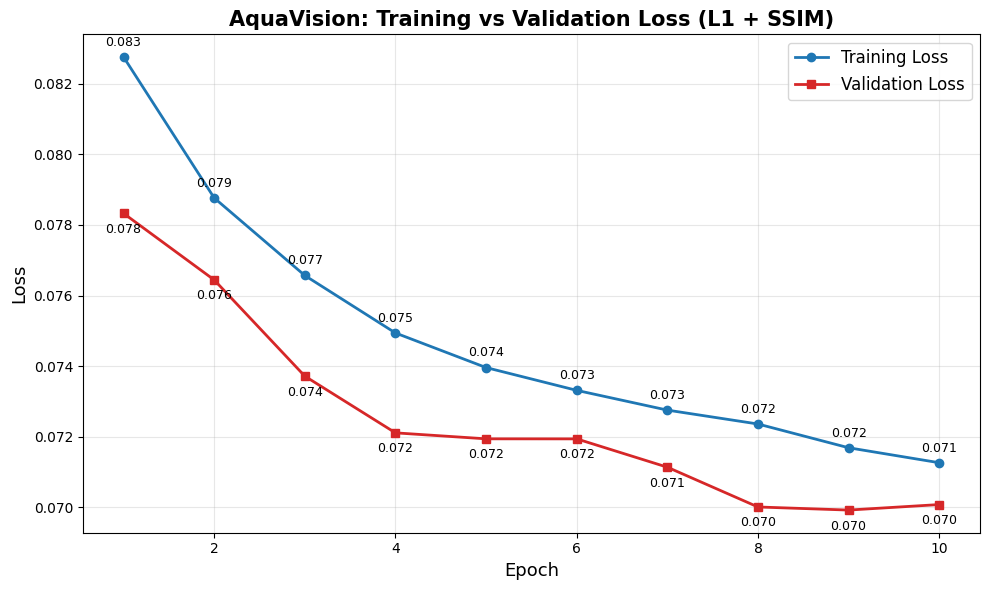

In [14]:
# CELL 14 — PLOT TRAINING AND VALIDATION LOSS
hist_df = pd.read_csv(HISTORY_PATH)
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(hist_df['epoch'], hist_df['train_loss'], 'o-', label='Training Loss', color='#1f77b4', linewidth=2)
ax.plot(hist_df['epoch'], hist_df['val_loss'],   's-', label='Validation Loss', color='#d62728', linewidth=2)
if len(hist_df) <= 15:
    for e, t, v in zip(hist_df['epoch'], hist_df['train_loss'], hist_df['val_loss']):
        ax.annotate(f"{t:.3f}", (e, t), textcoords="offset points", xytext=(0, 8), ha='center', fontsize=9)
        ax.annotate(f"{v:.3f}", (e, v), textcoords="offset points", xytext=(0, -14), ha='center', fontsize=9)
ax.set_title("AquaVision: Training vs Validation Loss (L1 + SSIM)", fontsize=15, fontweight='bold')
ax.set_xlabel("Epoch", fontsize=13); ax.set_ylabel("Loss", fontsize=13)
ax.legend(fontsize=12); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'training_validation_loss.png'), dpi=200)
plt.show()

In [15]:
#load best checkpoints and evaluate psnr,ssim
ck = torch.load(BEST_PATH, map_location=device)
model.load_state_dict(ck['model'])
model.eval()
print(f"Loaded best model from epoch {ck['epoch']} (val loss {ck['val_loss']:.4f})")

def to_np(t):   # [3,H,W] tensor -> [H,W,3] float32 in [0,1]
    return t.clamp(0, 1).permute(1, 2, 0).cpu().numpy().astype(np.float32)

rows, idx = [], 0
with torch.no_grad():
    for x, y in tqdm(test_loader, desc='Evaluating test set'):
        pred = model(x.to(device)).float().cpu()
        for j in range(x.size(0)):
            inp, ref, enh = to_np(x[j]), to_np(y[j]), to_np(pred[j])
            assert inp.shape == ref.shape == enh.shape
            rows.append({
                'index': idx,
                'input_path': test_df.loc[idx, 'input'],
                'category': test_df.loc[idx, 'category'],
                'psnr_original': sk_psnr(ref, inp, data_range=1.0),
                'psnr_enhanced': sk_psnr(ref, enh, data_range=1.0),
                'ssim_original': sk_ssim(ref, inp, channel_axis=2, data_range=1.0),
                'ssim_enhanced': sk_ssim(ref, enh, channel_axis=2, data_range=1.0),
            })
            idx += 1

results_df = pd.DataFrame(rows)
results_df.to_csv(os.path.join(RESULTS_DIR, 'evaluation_results.csv'), index=False)

metrics = {
    'num_test_images': int(len(results_df)),
    'avg_psnr_original': float(results_df['psnr_original'].mean()),
    'avg_psnr_enhanced': float(results_df['psnr_enhanced'].mean()),
    'avg_ssim_original': float(results_df['ssim_original'].mean()),
    'avg_ssim_enhanced': float(results_df['ssim_enhanced'].mean()),
}
metrics['psnr_improvement'] = metrics['avg_psnr_enhanced'] - metrics['avg_psnr_original']
metrics['ssim_improvement'] = metrics['avg_ssim_enhanced'] - metrics['avg_ssim_original']
with open(os.path.join(RESULTS_DIR, 'metrics_summary.json'), 'w') as f:
    json.dump(metrics, f, indent=2)

print("\n========== TEST SET RESULTS ==========")
print(f"Test images          : {metrics['num_test_images']}")
print(f"Avg PSNR  original   : {metrics['avg_psnr_original']:.3f} dB")
print(f"Avg PSNR  enhanced   : {metrics['avg_psnr_enhanced']:.3f} dB   (Δ {metrics['psnr_improvement']:+.3f} dB)")
print(f"Avg SSIM  original   : {metrics['avg_ssim_original']:.4f}")
print(f"Avg SSIM  enhanced   : {metrics['avg_ssim_enhanced']:.4f}   (Δ {metrics['ssim_improvement']:+.4f})")

Loaded best model from epoch 9 (val loss 0.0699)


Evaluating test set:   0%|          | 0/108 [00:00<?, ?it/s]


========== TEST SET RESULTS ==========
Test images          : 1716
Avg PSNR  original   : 17.136 dB
Avg PSNR  enhanced   : 23.696 dB   (Δ +6.560 dB)
Avg SSIM  original   : 0.7886
Avg SSIM  enhanced   : 0.8764   (Δ +0.0878)


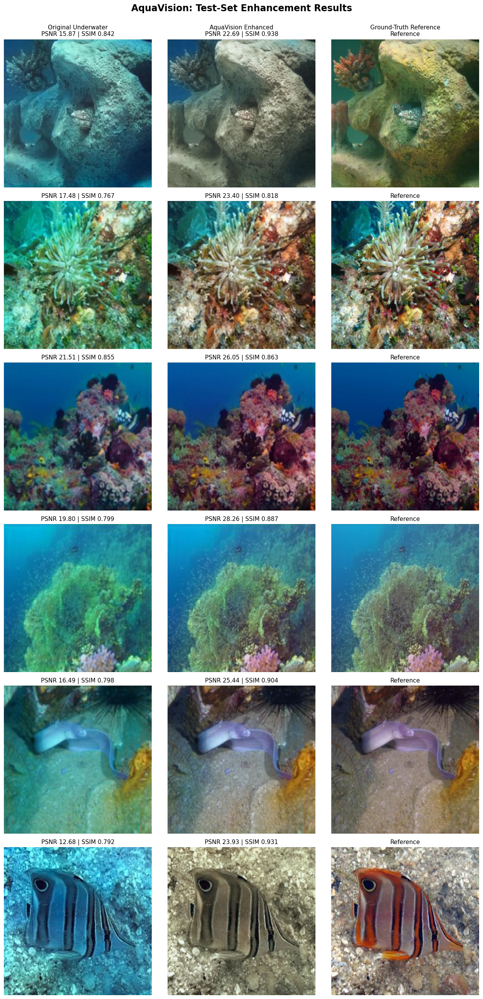

In [16]:
#CELL 16 — ORIGINAL vs ENHANCED vs REFERENCE COMPARISONS
n_samples = 6
sel = np.linspace(0, len(test_ds) - 1, n_samples).astype(int)

fig, axes = plt.subplots(n_samples, 3, figsize=(13, 4.3 * n_samples))
col_titles = ["Original Underwater", "AquaVision Enhanced", "Ground-Truth Reference"]
model.eval()
with torch.no_grad():
    for r, i in enumerate(sel):
        x, y = test_ds[i]
        pred = model(x.unsqueeze(0).to(device)).float().cpu()[0]
        res = results_df.loc[i]
        imgs = [to_np(x), to_np(pred), to_np(y)]
        subs = [f"PSNR {res.psnr_original:.2f} | SSIM {res.ssim_original:.3f}",
                f"PSNR {res.psnr_enhanced:.2f} | SSIM {res.ssim_enhanced:.3f}", "Reference"]
        for c in range(3):
            axes[r, c].imshow(imgs[c]); axes[r, c].axis('off')
            axes[r, c].set_title((col_titles[c] + "\n" if r == 0 else "") + subs[c], fontsize=11)
plt.suptitle("AquaVision: Test-Set Enhancement Results", fontsize=17, fontweight='bold', y=1.0)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'image_comparison.png'), dpi=150, bbox_inches='tight')
plt.show()

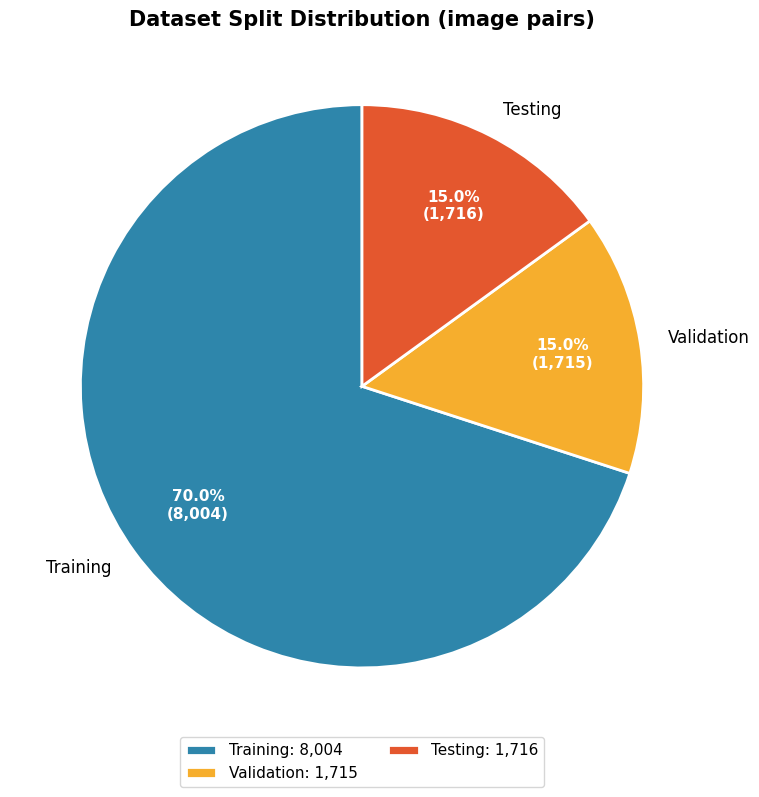

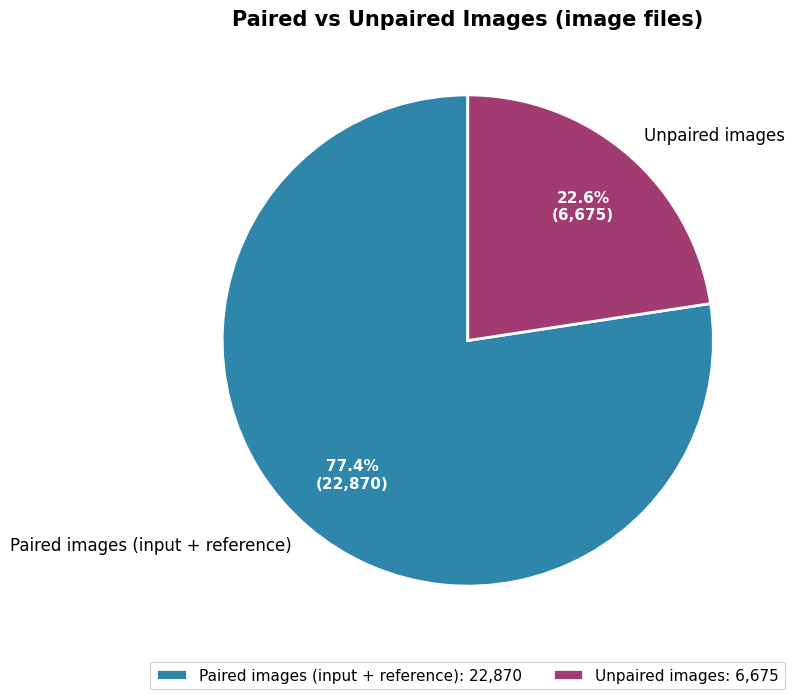

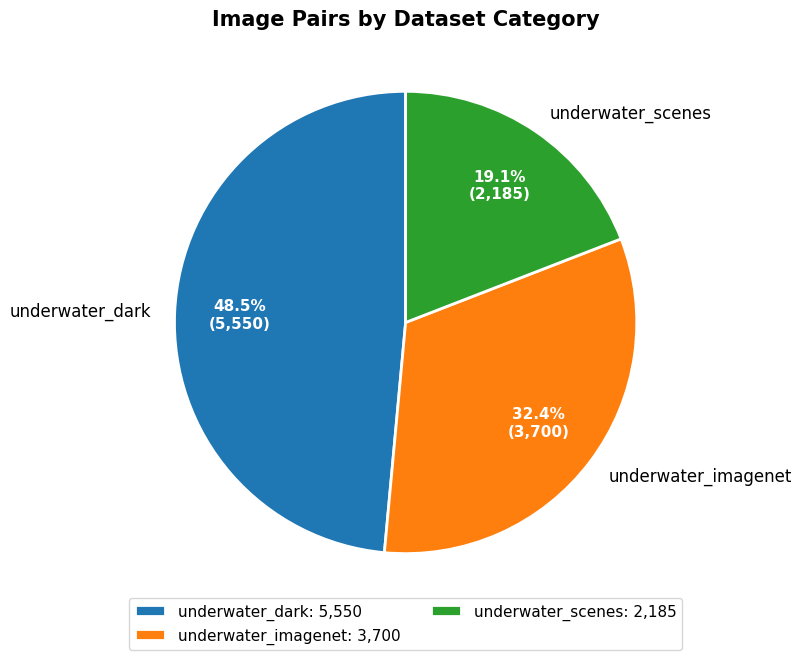

In [17]:
#DATASET DISTRIBUTION PIE CHARTS
def pie_chart(values, labels, title, fname, colors=None):
    pairs = [(v, l) for v, l in zip(values, labels) if v > 0]
    vals, labs = [p[0] for p in pairs], [p[1] for p in pairs]
    total = sum(vals)
    fig, ax = plt.subplots(figsize=(8, 8))
    wedges, texts, autotexts = ax.pie(
        vals, labels=labs, startangle=90, colors=colors, pctdistance=0.72,
        autopct=lambda p: f"{p:.1f}%\n({int(round(p * total / 100)):,})",
        wedgeprops=dict(edgecolor='white', linewidth=2), textprops={'fontsize': 12})
    for t in autotexts: t.set_fontweight('bold'); t.set_color('white'); t.set_fontsize(11)
    ax.legend(wedges, [f"{l}: {v:,}" for l, v in zip(labs, vals)], loc='lower center',
              bbox_to_anchor=(0.5, -0.08), ncol=2, fontsize=11)
    ax.set_title(title, fontsize=15, fontweight='bold')
    plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, fname), dpi=200, bbox_inches='tight'); plt.show()

# 1) Train / Val / Test split (pairs)
pie_chart([len(train_df), len(val_df), len(test_df)],
          ['Training', 'Validation', 'Testing'],
          "Dataset Split Distribution (image pairs)", 'pie_split_distribution.png',
          colors=['#2E86AB', '#F6AE2D', '#E4572E'])

# 2) Paired vs unpaired (individual image files)
pie_chart([2 * len(pairs_df), len(unpaired_paths)],
          ['Paired images (input + reference)', 'Unpaired images'],
          "Paired vs Unpaired Images (image files)", 'pie_paired_vs_unpaired.png',
          colors=['#2E86AB', '#A23B72'])

# 3) Pairs per dataset category/folder
cat_counts = pairs_df['category'].value_counts()
if len(cat_counts) > 1:
    pie_chart(cat_counts.values.tolist(), [os.path.basename(c) or c for c in cat_counts.index],
              "Image Pairs by Dataset Category", 'pie_category_distribution.png')
else:
    print("Only one category found — category pie chart skipped (not meaningful).")

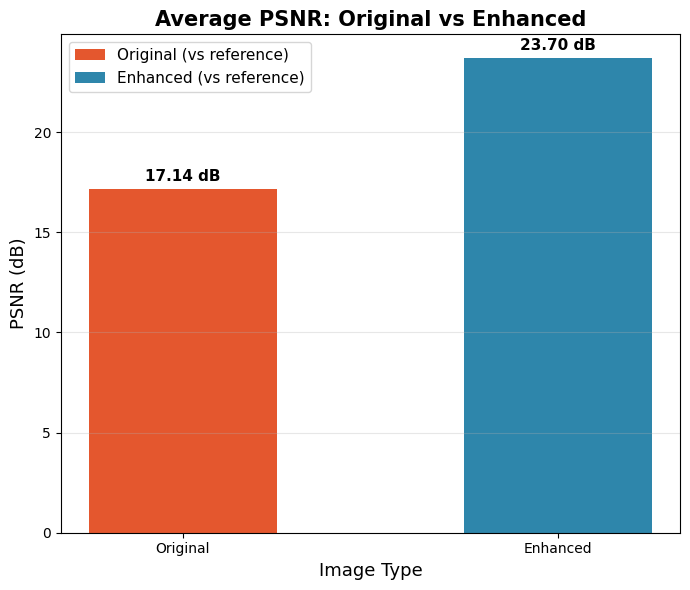

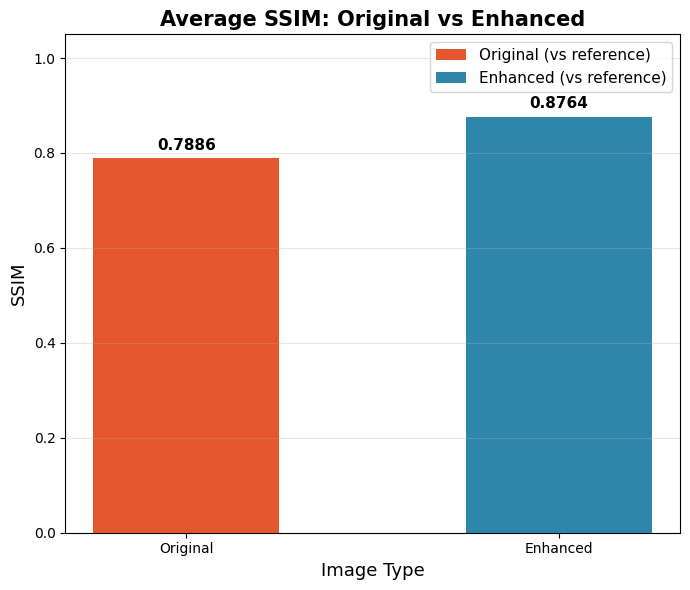

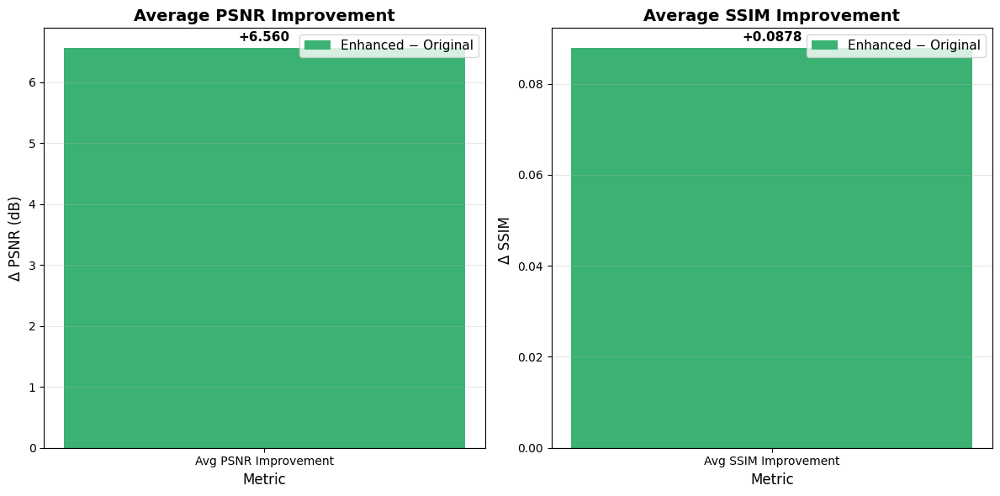

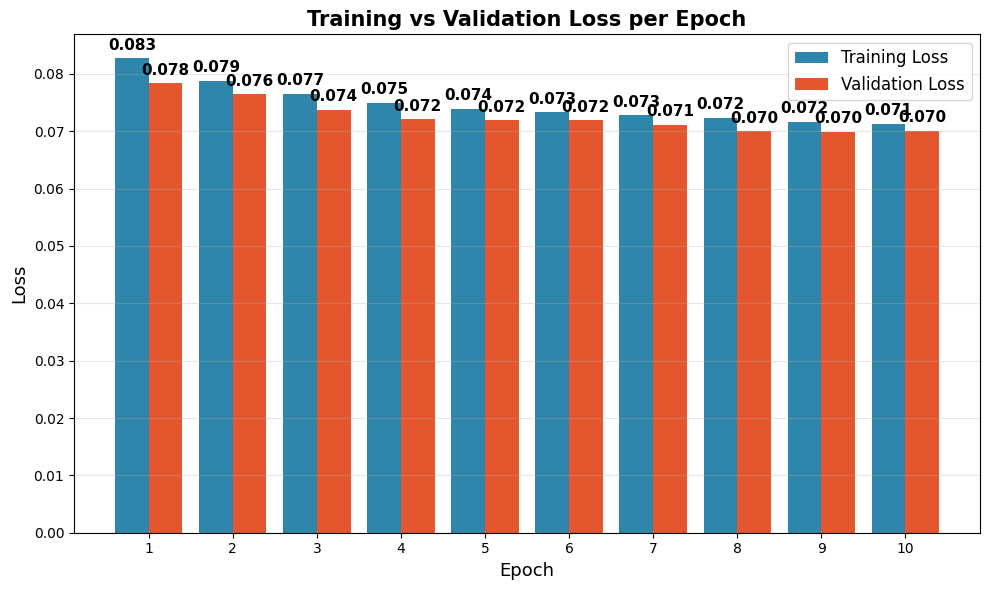

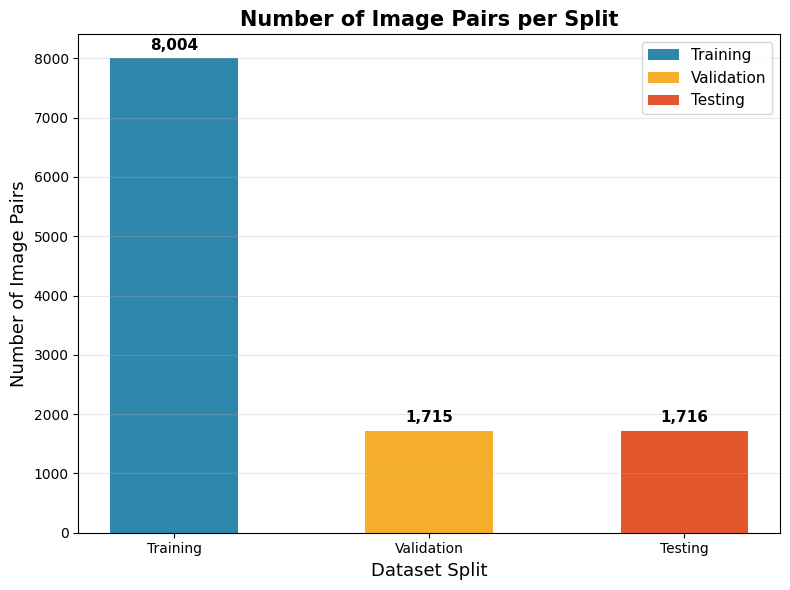

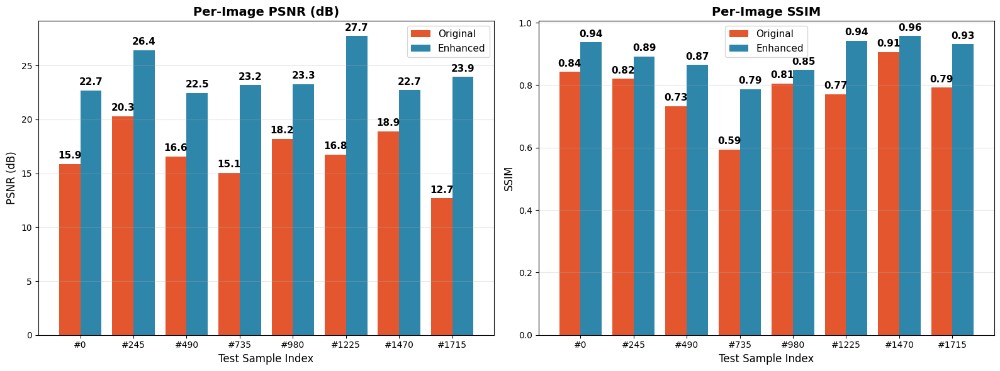

In [18]:
#PSNR, SSIM AND TRAINING BAR GRAPHS
def labeled_bars(ax, bars, fmt="{:.3f}"):
    for b in bars:
        h = b.get_height()
        ax.annotate(fmt.format(h), (b.get_x() + b.get_width() / 2, h), xytext=(0, 4),
                    textcoords='offset points', ha='center', va='bottom', fontsize=11, fontweight='bold')

def save(fig, name):
    fig.tight_layout(); fig.savefig(os.path.join(FIG_DIR, name), dpi=200, bbox_inches='tight'); plt.show()

# 1) PSNR original vs enhanced
fig, ax = plt.subplots(figsize=(7, 6))
b = ax.bar(['Original', 'Enhanced'], [metrics['avg_psnr_original'], metrics['avg_psnr_enhanced']], color=['#E4572E', '#2E86AB'], width=0.5)
labeled_bars(ax, b, "{:.2f} dB")
ax.set_title("Average PSNR: Original vs Enhanced", fontsize=15, fontweight='bold')
ax.set_xlabel("Image Type", fontsize=13); ax.set_ylabel("PSNR (dB)", fontsize=13)
ax.legend(b, ['Original (vs reference)', 'Enhanced (vs reference)'], fontsize=11); ax.grid(axis='y', alpha=0.3)
save(fig, 'bar_psnr_comparison.png')

# 2) SSIM original vs enhanced
fig, ax = plt.subplots(figsize=(7, 6))
b = ax.bar(['Original', 'Enhanced'], [metrics['avg_ssim_original'], metrics['avg_ssim_enhanced']], color=['#E4572E', '#2E86AB'], width=0.5)
labeled_bars(ax, b, "{:.4f}")
ax.set_title("Average SSIM: Original vs Enhanced", fontsize=15, fontweight='bold')
ax.set_xlabel("Image Type", fontsize=13); ax.set_ylabel("SSIM", fontsize=13)
ax.set_ylim(0, 1.05); ax.legend(b, ['Original (vs reference)', 'Enhanced (vs reference)'], fontsize=11); ax.grid(axis='y', alpha=0.3)
save(fig, 'bar_ssim_comparison.png')

# 3 & 4) Average improvements
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for ax, key, name, unit, fmt in [(axes[0], 'psnr_improvement', 'PSNR', 'dB', "{:+.3f}"), (axes[1], 'ssim_improvement', 'SSIM', '', "{:+.4f}")]:
    v = metrics[key]
    bar = ax.bar([f'Avg {name} Improvement'], [v], color='#3BB273' if v >= 0 else '#E4572E', width=0.4)
    labeled_bars(ax, bar, fmt)
    ax.axhline(0, color='black', linewidth=0.8)
    ax.set_title(f"Average {name} Improvement", fontsize=14, fontweight='bold')
    ax.set_xlabel("Metric", fontsize=12); ax.set_ylabel(f"Δ {name} {('(' + unit + ')') if unit else ''}", fontsize=12)
    ax.legend(bar, ['Enhanced − Original'], fontsize=11); ax.grid(axis='y', alpha=0.3)
save(fig, 'bar_improvements.png')

# 5) Training vs validation loss per epoch (last 20 epochs max)
h = hist_df.tail(20)
x = np.arange(len(h)); w = 0.4
fig, ax = plt.subplots(figsize=(max(10, len(h) * 0.7), 6))
b1 = ax.bar(x - w / 2, h['train_loss'], w, label='Training Loss', color='#2E86AB')
b2 = ax.bar(x + w / 2, h['val_loss'],   w, label='Validation Loss', color='#E4572E')
if len(h) <= 12:
    labeled_bars(ax, b1, "{:.3f}"); labeled_bars(ax, b2, "{:.3f}")
ax.set_xticks(x); ax.set_xticklabels(h['epoch'].astype(int))
ax.set_title("Training vs Validation Loss per Epoch", fontsize=15, fontweight='bold')
ax.set_xlabel("Epoch", fontsize=13); ax.set_ylabel("Loss", fontsize=13); ax.legend(fontsize=12); ax.grid(axis='y', alpha=0.3)
save(fig, 'bar_train_val_loss.png')

# 6) Number of images in each split
fig, ax = plt.subplots(figsize=(8, 6))
counts = [len(train_df), len(val_df), len(test_df)]
b = ax.bar(['Training', 'Validation', 'Testing'], counts, color=['#2E86AB', '#F6AE2D', '#E4572E'], width=0.5)
labeled_bars(ax, b, "{:,.0f}")
ax.set_title("Number of Image Pairs per Split", fontsize=15, fontweight='bold')
ax.set_xlabel("Dataset Split", fontsize=13); ax.set_ylabel("Number of Image Pairs", fontsize=13)
ax.legend(b, ['Training', 'Validation', 'Testing'], fontsize=11); ax.grid(axis='y', alpha=0.3)
save(fig, 'bar_split_counts.png')

# 7) Per-image PSNR / SSIM for selected test samples
sel_idx = np.linspace(0, len(results_df) - 1, 8).astype(int)
s = results_df.loc[sel_idx]
x = np.arange(len(s))
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, (co, ce, nm, fmt) in zip(axes, [('psnr_original', 'psnr_enhanced', 'PSNR (dB)', "{:.1f}"), ('ssim_original', 'ssim_enhanced', 'SSIM', "{:.2f}")]):
    b1 = ax.bar(x - 0.2, s[co], 0.4, label='Original', color='#E4572E'); b2 = ax.bar(x + 0.2, s[ce], 0.4, label='Enhanced', color='#2E86AB')
    labeled_bars(ax, b1, fmt); labeled_bars(ax, b2, fmt)
    ax.set_xticks(x); ax.set_xticklabels([f"#{i}" for i in s['index']])
    ax.set_title(f"Per-Image {nm}", fontsize=14, fontweight='bold'); ax.set_xlabel("Test Sample Index", fontsize=12); ax.set_ylabel(nm, fontsize=12)
    ax.legend(fontsize=11); ax.grid(axis='y', alpha=0.3)
save(fig, 'bar_per_image_metrics.png')

In [19]:
#summary
n_params = count_params(model)
best_epoch = int(hist_df.loc[hist_df['val_loss'].idxmin(), 'epoch'])
verdict_p = "improved" if metrics['psnr_improvement'] > 0 else "did NOT improve"
verdict_s = "improved" if metrics['ssim_improvement'] > 0 else "did NOT improve"

summary = f"""
=====================================================================
 AQUAVISION: DEEP LEARNING FRAMEWORK FOR UNDERWATER IMAGE ENHANCEMENT
 FINAL EXPERIMENTAL SUMMARY
=====================================================================
Model            : DAE-UNet (ResNet18 encoder, residual decoder, skip connections)
Trainable params : {n_params:,}
Dataset          : EUVP (Kaggle: pamuduranasinghe/euvp-dataset)
Image size       : {IMG_SIZE} x {IMG_SIZE}
Total pairs      : {len(pairs_df):,}   | Unpaired images (unused for metrics): {len(unpaired_paths):,}
Split (pairs)    : Train {len(train_df):,} | Val {len(val_df):,} | Test {len(test_df):,}
Loss / Optimizer : L1 + {SSIM_WEIGHT} * (1 - SSIM) | Adam (lr={LR}) | ReduceLROnPlateau
Mixed precision  : {use_amp} | Device: {device}
Epochs trained   : {len(hist_df)} (best validation loss at epoch {best_epoch})
Mode             : {'QUICK TEST (not a final result)' if QUICK_TEST else 'FULL TRAINING'}

--------------- TEST-SET RESULTS ({metrics['num_test_images']} images) ---------------
Avg PSNR  original : {metrics['avg_psnr_original']:.3f} dB
Avg PSNR  enhanced : {metrics['avg_psnr_enhanced']:.3f} dB  (change {metrics['psnr_improvement']:+.3f} dB)
Avg SSIM  original : {metrics['avg_ssim_original']:.4f}
Avg SSIM  enhanced : {metrics['avg_ssim_enhanced']:.4f}  (change {metrics['ssim_improvement']:+.4f})

PSNR {verdict_p}; SSIM {verdict_s} relative to the unprocessed underwater images.
All values were measured on the held-out test set only.
=====================================================================
"""
print(summary)
with open(os.path.join(RESULTS_DIR, 'final_experimental_summary.txt'), 'w') as f:
    f.write(summary)
print("✅ Saved: final_experimental_summary.txt")


 AQUAVISION: DEEP LEARNING FRAMEWORK FOR UNDERWATER IMAGE ENHANCEMENT
 FINAL EXPERIMENTAL SUMMARY
Model            : DAE-UNet (ResNet18 encoder, residual decoder, skip connections)
Trainable params : 14,684,707
Dataset          : EUVP (Kaggle: pamuduranasinghe/euvp-dataset)
Image size       : 256 x 256
Total pairs      : 11,435   | Unpaired images (unused for metrics): 6,675
Split (pairs)    : Train 8,004 | Val 1,715 | Test 1,716
Loss / Optimizer : L1 + 0.15 * (1 - SSIM) | Adam (lr=0.0002) | ReduceLROnPlateau
Mixed precision  : True | Device: cuda
Epochs trained   : 10 (best validation loss at epoch 9)
Mode             : FULL TRAINING

--------------- TEST-SET RESULTS (1716 images) ---------------
Avg PSNR  original : 17.136 dB
Avg PSNR  enhanced : 23.696 dB  (change +6.560 dB)
Avg SSIM  original : 0.7886
Avg SSIM  enhanced : 0.8764  (change +0.0878)

PSNR improved; SSIM improved relative to the unprocessed underwater images.
All values were measured on the held-out test set only.

✅ 